alt.Chart(...)
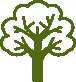
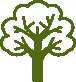
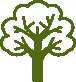
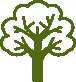
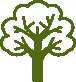
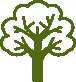
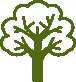
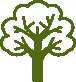
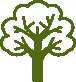
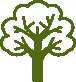
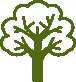
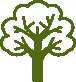
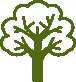
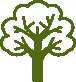
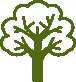
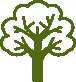
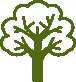
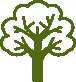
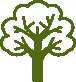
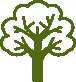
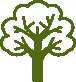
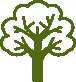
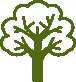
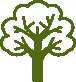
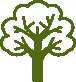
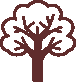
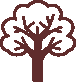
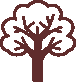
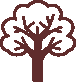
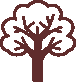
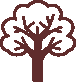
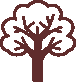
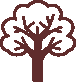
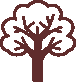
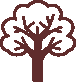
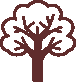
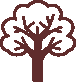
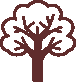
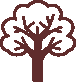
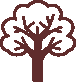
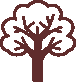

In [ ]:
import base64
from io import BytesIO
import os
import altair as alt
import numpy as np
import pandas as pd
from PIL import Image

# 1. Intentar cargar el archivo con su nombre real (probando .csv o .xlsx)
file_base = "/content/Áreas verdes por habitante en zonas urbanas (limpia)"

if os.path.exists(f"{file_base}.csv"):
  df = pd.read_csv(f"{file_base}.csv")
elif os.path.exists(f"{file_base}.xlsx"):
  df = pd.read_excel(f"{file_base}.xlsx")
else:
  raise FileNotFoundError(
      "Por favor sube el archivo 'Áreas verdes por habitante en zonas urbanas"
      " (limpia)' como .csv o .xlsx a la carpeta /content/"
  )

# 2. Convertir valores con comas decimales a tipo flotante
if df["VALOR DEL INDICADOR EN M2"].dtype == "O":
  df["VALOR DEL INDICADOR EN M2"] = (
      df["VALOR DEL INDICADOR EN M2"].str.replace(",", ".").astype(float)
  )

# 3. Mantener solo COMUNA y el Indicador
df = df[["COMUNA", "VALOR DEL INDICADOR EN M2"]].copy()


# 4. Función para limpiar el fondo, recortar bordes vacíos, aplicar color RGB y generar URI Base64
def crear_arbol_uri(image_path, rgb_color):
  img = Image.open(image_path).convert("RGBA")
  data = np.array(img)
  r, g, b, a = data[:, :, 0], data[:, :, 1], data[:, :, 2], data[:, :, 3]

  # Detectar píxeles claros (fondo) y volverlos transparentes
  es_fondo = (r > 200) & (g > 200) & (b > 200)

  data[~es_fondo, 0] = rgb_color[0]
  data[~es_fondo, 1] = rgb_color[1]
  data[~es_fondo, 2] = rgb_color[2]
  data[es_fondo, 3] = 0

  img_procesada = Image.fromarray(data)
  # Recortar márgenes transparentes sobrantes para aprovechar el 100% del tamaño
  bbox = img_procesada.getbbox()
  if bbox:
    img_procesada = img_procesada.crop(bbox)

  buffered = BytesIO()
  img_procesada.save(buffered, format="PNG")
  encoded = base64.b64encode(buffered.getvalue()).decode("utf-8")
  return f"data:image/png;base64,{encoded}"


tree_image_path = "/content/pictograma arbol.png"

# #4F6915 -> RGB(79, 105, 21) | #602C2C -> RGB(96, 44, 44)
arbol_verde_uri = crear_arbol_uri(tree_image_path, (79, 105, 21))
arbol_alerta_uri = crear_arbol_uri(tree_image_path, (96, 44, 44))

# Asignar la imagen correspondiente a cada comuna (< 5 m² usa #602C2C)
df["imagen_url"] = np.where(
    df["VALOR DEL INDICADOR EN M2"] < 5, arbol_alerta_uri, arbol_verde_uri
)

# 5. Cálculo dinámico del tamaño para que los árboles sean grandes y NUNCA choquen
TAMANO_ARBOL = 20  # Tamaño de cada árbol en píxeles (puedes subirlo a 22 o 24)
SEPARACION = 3  # Espacio libre en píxeles entre árbol y árbol (vertical y horizontal)

num_comunas = df["COMUNA"].nunique()
max_arboles = int(np.ceil(df["VALOR DEL INDICADOR EN M2"].max()))

# El ancho y alto se adaptan exactamente al tamaño del árbol + separación
chart_width = max(950, num_comunas * (TAMANO_ARBOL + SEPARACION + 4))
chart_height = max(550, max_arboles * (TAMANO_ARBOL + SEPARACION))

# 6. Definir las selecciones para interactividad (Altair 5+)
select = alt.selection_point(name="select", fields=["COMUNA"], on="click")
highlight = alt.selection_point(
    name="highlight", fields=["COMUNA"], on="pointerover", empty=False
)

# 7. Construir el gráfico de pictogramas (1 árbol = 1 m²)
chart = (
    alt.Chart(df, height=chart_height, width=chart_width)
    .transform_calculate(
        num_arboles="round(datum['VALOR DEL INDICADOR EN M2'])"
    )
    .transform_calculate(indice_arbol="sequence(1, datum.num_arboles + 1)")
    .transform_flatten(["indice_arbol"])
    .mark_image(
        width=TAMANO_ARBOL,
        height=TAMANO_ARBOL,
        cursor="pointer",
    )
    .encode(
        x=alt.X(
            "COMUNA:O",
            title="Comuna",
            sort=None,
            axis=alt.Axis(labelAngle=-45),
        ),
        y=alt.Y(
            "indice_arbol:Q",
            title="Metros cuadrados de áreas verdes (1 árbol = 1 m²)",
            axis=alt.Axis(tickMinStep=1),
            scale=alt.Scale(domain=[0.5, max_arboles + 0.5]),
        ),
        url=alt.Url("imagen_url:N"),
        opacity=alt.when(select | highlight)
        .then(alt.value(1))
        .otherwise(alt.value(0.85)),
        tooltip=[
            alt.Tooltip("COMUNA:N", title="Comuna"),
            alt.Tooltip("VALOR DEL INDICADOR EN M2:Q", title="Indicador (m²)"),
            alt.Tooltip("num_arboles:Q", title="Total Árboles (1 m² c/u)"),
        ],
    )
    .add_params(select, highlight)
)

chart